# Machine Learning Starter Guide: SSN 2026 Netball Data Hack

This notebook will help you:

1. Understand three basic machine learning (ML) models: **Linear Regression**, **Logistic Regression** and **Neural Networks**
2. Use **NSW EduChat** to guide you as you change working code to answer your own questions
3. Make charts with **matplotlib**

**Dataset:** `SSN_2026_Player_Stats_Final.csv` has 103 netball players, one row per player, with season totals for Rounds 1–12.

> **How to use this notebook:** read a concept, run the **starter code**, then copy a prompt into EduChat with your code and let it guide you through the changes. Run each cell with **Shift + Enter**.

## Step 1: Load the data

Run the cell below. It loads the data so every later cell can use `df`.

In [2]:
import pandas as pd

df = pd.read_csv("SSN_2026_Player_Stats_Final.csv")
df.head()

,position,team,first_name,surname,games,quarters,minutes,goals,attempts,acc_pct,one_pt_goals,super_shot_goals,goal_assists,feeds,intercepts,deflections,gains,rebounds,penalties
0,GS,West Coast Fever,Romelda,Aiken-George,12,46,649,502,591,84.9,496,6,10,34,0,2,0,66,32
1,GS,Queensland Firebirds,Mary,Cholhok,11,46,615,448,562,79.7,441,7,7,25,0,3,0,73,28
2,GS,Melbourne Vixens,Sophie,Garbin,11,48,678,412,461,89.4,410,2,82,126,1,2,2,28,46
3,GS,GIANTS Netball,Matisse,Letherbarrow,11,45,578,270,333,81.1,225,45,36,60,1,1,1,16,22
4,GS,Melbourne Mavericks,Shimona,Nelson,12,46,611,448,484,92.6,445,3,9,12,0,0,0,25,20


### The columns at a glance

| Column | Meaning |
| --- | --- |
| `position` | GS, GA, WA, C, WD, GD, GK |
| `team` | One of 8 clubs |
| `first_name`, `surname` | Player name |
| `games`, `quarters`, `minutes` | How much the player played |
| `goals`, `attempts`, `acc_pct` | Shooting (acc_pct = accuracy %) |
| `one_pt_goals`, `super_shot_goals` | 1-point and 2-point goals |
| `goal_assists`, `feeds` | Attacking passes |
| `intercepts`, `deflections`, `gains`, `rebounds` | Defence |
| `penalties` | Penalties given away |

**Watch out for these:**
- 72 players have `attempts = 0`, so their `acc_pct` is 0. Remove them before you study accuracy.
- 2 players have `minutes = 0`. Remove them before you divide by minutes.
- Players who play more minutes have bigger totals. Compare players **per 60 minutes** to make it fair.

---
## Step 2: Working with AI (NSW EduChat)

EduChat is a **tutor**. It won't write the code for you, but it **will guide you step by step** to change code you already have. That's great for you, because you'll understand every line and can explain it to the judges.

**The method:** every model below has **working starter code**. Run it, paste it into EduChat, say what you want to change, and let it guide you.

### 1. Start every new EduChat chat with this message

```
I'm a high school student at a netball data hack, new to Python. My pandas DataFrame df is loaded from SSN_2026_Player_Stats_Final.csv. Columns: position, team, minutes, goals, attempts, acc_pct, goal_assists, feeds, intercepts, deflections, gains, rebounds, penalties. Please guide me step by step to change my own code.
```

### 2. How a good prompt is built

| # | Include | Example |
| --- | --- | --- |
| 1 | **Say it's your netball code** | `This is my netball code.` |
| 2 | **What you want to change** | `I want to predict gains instead of goals.` |
| 3 | **The exact column names** | `The columns are "deflections" and "gains".` |
| 4 | **Ask for guidance** | `Can you guide me step by step?` |
| 5 | **Paste your working code** | *(copy it from the code cell)* |

### 3. The conversation loop

EduChat will ask you questions. **That's how it works.** Each answer gets you one step closer.

1. **Paste** your code and say what you want to change
2. **Answer** EduChat's question. Have a go, even if you're unsure!
3. **Change** your code cell and **run it**
4. **Tell EduChat** what happened, then repeat until it's done

| If EduChat asks... | You can reply... |
| --- | --- |
| *"Which columns should we use?"* | Name them exactly: *"deflections and gains"* |
| *"Can you try rewriting this line?"* | Type your attempt: *"X = df[["deflections"]]"* |
| *"What do you think this line does?"* | Explain in your own words. A guess is fine! |
| *"Which model would suit this?"* | Guess with a reason: *"Logistic regression, because it's yes/no?"* |
| You ran it and it worked | *"That worked! What's the next step?"* |
| You ran it and got an error | *"I changed it to ... and got this error: ... What should I check?"* |
| You've tried but you're stuck | *"I tried ... but I'm stuck. Can you give me a bigger hint?"* |
| It talks about the wrong sport or data | *"This is netball data. The columns are ..."* |

**Tips:**
- 📋 **Copy the cell first** so you keep a working version.
- 1️⃣ **Make one change at a time**, and run the code after every step.
- 🔄 **Going in circles?** Start a **new chat**, send the starter message, then your prompt.
- ⚠️ **Check your results.** Do they make sense for netball?
- 🔒 **Never share personal information** in a chat.

---
## Step 3: Key ML ideas

| Term | Meaning |
| --- | --- |
| **Feature (X)** | An input column the model learns from, e.g. `attempts` |
| **Target (y)** | The thing you want to predict, e.g. `goals` |
| **Training data** | Rows the model learns from (usually 80%) |
| **Test data** | Rows kept aside to check the model (usually 20%) |
| **Regression** | Predicting a **number** (e.g. how many goals) |
| **Classification** | Predicting a **category** (e.g. attacker or defender) |
| **Overfitting** | The model memorises training data but fails on new data |

> We only have 103 rows, which is small for ML. Keep models simple and don't trust results that look too perfect.

---
## Model 1: Linear Regression (predicting a number)

**Idea:** draw the best straight line through the data.
$$y = m x + b$$
For example: *more shot attempts → more goals.* The model finds the slope `m` and the intercept `b`.

**Use it when:** the target is a number and the relationship looks roughly like a straight line.

**How to judge it:**
- **R²** goes from 0 to 1. Closer to 1 means the line fits better.
- **MAE** (mean absolute error) is the average size of the model's mistakes.

**Run the starter code below.** It predicts goals from attempts. Then pick a prompt, paste it into EduChat with your code, and change it step by step.

### Prompts to copy

**1A: Make it a fair test**
```
This is my netball code. I want to add a train/test split so I test the model on players it hasn't seen. Can you guide me step by step?
```

**1B: Predict something else**
```
This is my netball code. I want to predict gains from deflections instead of goals from attempts. The columns are "deflections" and "gains". Can you guide me step by step?
```

**1C: Use more stats**
```
This is my netball code. I want to predict gains using deflections, intercepts and rebounds together. Can you guide me step by step?
```

**1D: Measure the mistakes**
```
This is my netball code. I want to also print the MAE so I know how many goals the predictions are off by. Can you guide me?
```

R²: 0.99


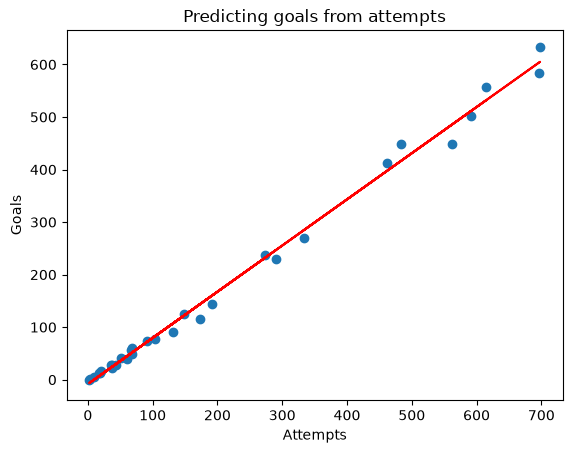

In [3]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

shooters = df[df["attempts"] > 0]
X = shooters[["attempts"]]
y = shooters["goals"]

model = LinearRegression()
model.fit(X, y)
print("R²:", round(model.score(X, y), 2))

plt.scatter(shooters["attempts"], shooters["goals"])
plt.plot(shooters["attempts"], model.predict(X), color="red")
plt.title("Predicting goals from attempts")
plt.xlabel("Attempts")
plt.ylabel("Goals")
plt.show()

---
## Model 2: Logistic Regression (predicting a yes/no category)

**Idea:** even though the name says "regression", this model is used for **classification**. It outputs a **probability** between 0 and 1 using an S-shaped curve, the *sigmoid*:
$$p = \frac{1}{1 + e^{-(mx + b)}}$$
If $p > 0.5$, the model predicts "yes".

**Example question:** *Is this player an attacker (GS, GA, WA, C) or a defender (WD, GD, GK), based only on their stats?*

**How to judge it:**
- **Accuracy** is the % of predictions that are correct.
- A **confusion matrix** shows which classes the model mixes up.

**Run the starter code below.** It predicts attacker or defender from feeds and gains. Then change it with EduChat's help.

### Prompts to copy

**2A: Use more stats**
```
This is my netball code. I want to add goals, rebounds and penalties as extra features. Can you guide me step by step?
```

**2B: Make it a fair test**
```
This is my netball code. I want to add a train/test split and check the accuracy on the test players. Can you guide me step by step?
```

**2C: See the mistakes**
```
This is my netball code. I want to show a confusion matrix chart so I can see which players it gets wrong. Can you guide me step by step?
```

**2D: Make it fair for minutes**
```
This is my netball code. Players with more minutes have bigger stats. I want to use per-60-minute stats instead. Can you guide me step by step?
```

In [4]:
from sklearn.linear_model import LogisticRegression

df["is_attacker"] = df["position"].isin(["GS", "GA", "WA", "C"]).astype(int)
X = df[["feeds", "gains"]]
y = df["is_attacker"]

model = LogisticRegression(max_iter=1000)
model.fit(X, y)
print("Accuracy:", round(model.score(X, y) * 100), "%")

Accuracy: 94 %


---
## Model 3: Neural Network (learning complex patterns)

**Idea:** a neural network is layers of connected "neurons", loosely inspired by the brain.

```
Inputs (stats)  →  Hidden layer(s)  →  Output (prediction)
 feeds, gains...     neurons learn        position
                     patterns
```

- Each connection has a **weight**. Training adjusts the weights to reduce errors.
- **Hidden layers** let the network learn patterns that aren't straight lines.
- Neural networks need **scaled data** (similar number ranges), so we use `StandardScaler`.

**Example question:** *Can the network predict a player's exact position (all 7 positions) from their stats?*

> With only 103 players, a neural network may not beat logistic regression. That's a good thing to test and report!

**Run the starter code below.** It predicts each player's position. Then change it with EduChat's help.

### Prompts to copy

**3A: Make it a fair test**
```
This is my netball neural network. I want to add a train/test split and compare training accuracy with test accuracy. Can you guide me step by step?
```

**3B: Change the network**
```
This is my netball neural network. I want to try different hidden layer sizes and see which works best. Can you guide me?
```

**3C: An easier question**
```
This is my netball neural network. I want to predict is_attacker (yes/no) instead of position, so I can compare it with logistic regression. Can you guide me step by step?
```

**3D: Advanced, using Keras**
```
This is my netball neural network using scikit-learn. I want to rebuild it using keras. Can you guide me step by step?
```

In [5]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

X = df[["goals", "feeds", "gains", "rebounds", "penalties"]]
y = df["position"]

model = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(10,), solver="lbfgs", alpha=1.0, max_iter=5000, random_state=1),
)
model.fit(X, y)
print("Accuracy:", round(model.score(X, y) * 100), "%")

Accuracy: 73 %


---
## Step 4: Charts with matplotlib

Good charts help you **find patterns before modelling** and **explain results** to judges.

| Chart | Best for | Example |
| --- | --- | --- |
| Bar | Comparing groups | Total goals per team |
| Scatter | Relationship between 2 numbers | attempts vs goals |
| Histogram | How values are spread | minutes played |
| Box plot | Comparing spread across groups | penalties by position |

**Run the starter chart below**, then change it with EduChat's help. Notebook 1 has more chart code you can start from.

### Prompts to copy

**Change the data**
```
This is my netball bar chart. I want to show total penalties by position instead of goals by team. The columns are "position" and "penalties". Can you guide me step by step?
```

**Change the chart type**
```
This is my netball bar chart. I want to change it to a box plot of penalties for each position. Can you guide me step by step?
```

**Show a relationship**
```
This is my netball bar chart. I want to change it to a scatter plot of feeds vs gains, with a different colour for each position. Can you guide me step by step?
```

**Show all the links at once**
```
This is my netball chart. I want to make a heatmap of the correlations between all numeric columns. Can you guide me step by step?
```

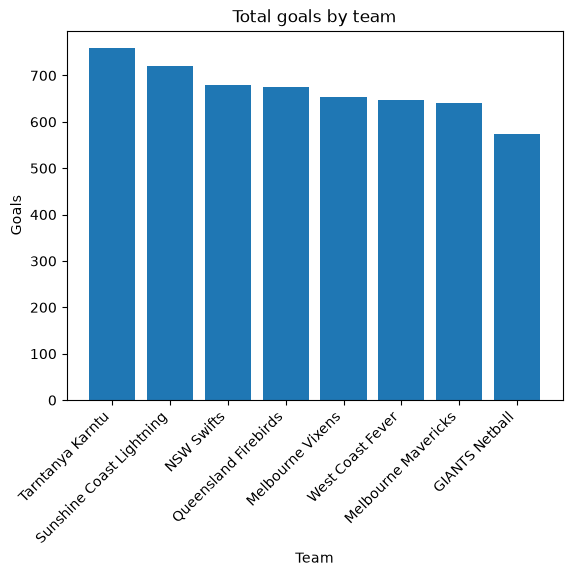

In [6]:
import matplotlib.pyplot as plt

team_goals = df.groupby("team")["goals"].sum().sort_values(ascending=False)

plt.bar(team_goals.index, team_goals.values)
plt.title("Total goals by team")
plt.xlabel("Team")
plt.ylabel("Goals")
plt.xticks(rotation=45, ha="right")
plt.show()

---
## Step 5: Prompts for when you're stuck

| Situation | Prompt |
| --- | --- |
| Error message | `I got this error in my netball code: <paste error>. Can you help me work out what's wrong?` |
| My change didn't work | `I tried to change my code like this: <paste code>. It doesn't work. What should I check?` |
| Don't understand code | `Can you help me understand what each line of this code does? <paste code>` |
| Want to explain results | `My LinearRegression has R² = 0.85 predicting goals from attempts. Can you help me understand what this means?` |
| Choosing a model | `I want to predict <target> from <columns>. Can you help me decide between linear regression, logistic regression and a neural network?` |
| Improving a model | `My LogisticRegression accuracy is 70% predicting attacker vs defender. Can you help me think of ways to improve it?` |

> **Remember:** a good data hack project tells a **story**: a question, a chart, a model, and what you found out.